# Nome: Emanuel Victor da Silva Favorato
# RA: 850560

In [1]:
# Importando bibliotecas
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
from scipy.stats import halfnorm # Meio normal padrão por default
from scipy.stats import kstest, chisquare

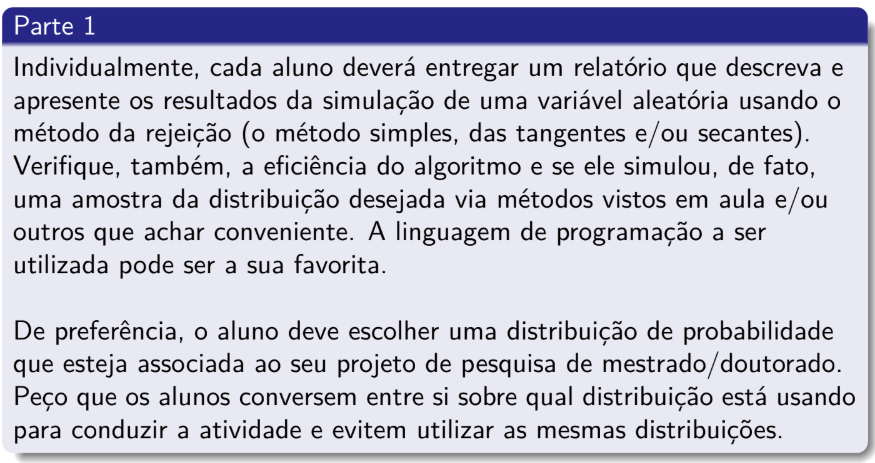

**Problema:** queremos simular valores simular valores de uma distribuição meio normal padrão utilizando os métodos da transformada inversa e de rejeição simples. A função densidade de probabilidade de uma distribuição meio normal é dada por:

$$
X\sim \operatorname{Half-Normal}(\mu,\sigma^2),
$$

$$
f_X(x)=
\begin{cases}
\dfrac{2}{\sigma\sqrt{2\pi}}
\exp\left(-\dfrac{(x - \mu)^2}{2\sigma^2}\right), & x\geq 0,\\[6pt]
0, & x<0.
\end{cases}
$$

Por sua vez, a distribuição meio normal padrão constitui um caso particular da família de distribuições anterior, tal que $\mu = 0$ e $\sigma^2 = 1$.

**Observação:** ao contrário do que ocorre na distribuição normal usual, os parâmetros $\mu$ e $\sigma^2$ não constituem a média e variância dessa distribuição, sendo esses parâmetros importados da distribuição normal completa. A média e variância da meio normal são dadas por:

$$
\mathbb{E}(X) = \frac{\sigma\sqrt{2}}{\sqrt{\pi}},
\quad
\operatorname{Var}(X) = \sigma^2\left(1 - \frac{2}{\pi}\right).
$$

### **1. Método da transformada inversa**

Vamos considerar a função densidade acumulada da distribuição meio normal padrão, dada por:

$$
F_X(x)=2\Phi(x)-1,\qquad x\geq 0,
$$

em que $\Phi$ é a função densidade acumulada da distribuição normal padrão.

Considerando uma variável aleatória $U\sim \operatorname{Uniforme}(0,1)$. Pelo método da transformada inversa, temos:

$$
U=F_X(X)=2\Phi(X)-1.
$$

Agora, vamos isolar $\Phi(X)$

$$
\Phi(X)=\frac{U+1}{2}.
$$

Invertendo a acumulada da distribuição normal padrão, temos:

$$
\boxed{X=\Phi^{-1}\left(\frac{U+1}{2}\right)}.
$$

Assim, obtemos o seguinte algoritmo de simulação:

1. Geramos um valor da variável $U\sim \operatorname{Uniforme}(0,1)$.
2. Calcula-se o valor de $X=\Phi^{-1}((U+1)/2)$.
3. Repetimos os passos 1 e 2 n vezes para obter uma amostra simulada da distribuição meio normal padrão.

In [2]:
np.random.seed(850560) # Fixando a semente
n = 10000 # Tamanho da amostra simulada

# Gerando probabilidades de uma U(0,1)
U = np.random.uniform(0, 1, n)

# Transformada inversa
X_inverse = norm.ppf((U + 1) / 2)

# Apresentando os dados simulados
X_inverse

array([0.08173196, 0.01837905, 1.7786646 , ..., 0.10766132, 2.18733829,
       1.50760969])

In [3]:
print("A média amostral considerando a transformada inversa é de:", round(X_inverse.mean(), 4))
print("A variância amostral considerando a transformada inversa é de:", round(X_inverse.var(), 4))

A média amostral considerando a transformada inversa é de: 0.7846
A variância amostral considerando a transformada inversa é de: 0.354


In [4]:
print("A média da distribuição meio normal é de:", round(halfnorm.mean(), 4))
print("A variância da distribuição meio normal é de:", round(halfnorm.var(), 4))

A média da distribuição meio normal é de: 0.7979
A variância da distribuição meio normal é de: 0.3634


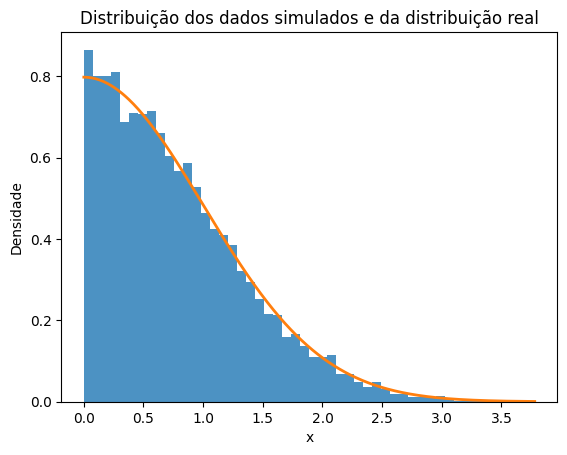

In [5]:
# Plotando o histograma para os dados simulados
plt.hist(X_inverse, bins=50, density=True, alpha=0.8)

x = np.linspace(0, max(X_inverse), 500) # Suavizador da meio normal
plt.plot(x, halfnorm.pdf(x), linewidth=2) # Plotando a distribuição meio normal padrão

plt.xlabel("x")
plt.ylabel("Densidade")
plt.title("Distribuição dos dados simulados e da distribuição real")
plt.show()

## **2. Método da rejeição simples**

Considerando a função densidade de probabilidade da distribuição meio normal padrão, dada por:

$$
f(x)=
\begin{cases}
\sqrt{\dfrac{2}{\pi}}\exp\left(-\dfrac{x^2}{2}\right), & x\geq 0,\\[6pt]
0, & x<0.
\end{cases}
$$

Cuja média e variância são:

$$
\mathbb{E}(X)=\sqrt{\frac{2}{\pi}},
\quad
\operatorname{Var}(X)=1-\frac{2}{\pi}.
$$

### Passo 1: propor uma envelope

Queremos simular esta distribuição a partir de uma função conhecida mais simples, e que seja envelope dela. Para isso, foi proposta a distribuição Exponencial(1), a qual possui suporte no mesmo espaço paramétrico da distribuição meio normal e cuja função densidade de probabilidade é escrita como:

$$
g(x)=
\begin{cases}
e^{-x}, & x\geq 0,\\
0, & x<0.
\end{cases}
$$

Entretanto, como pode ser verificado no gráfico abaixo, a distribuição Exponencial(1) por si só não é envelope para a distribuição meio normal padrão. Para isso, será necessário multiplicá-la por uma constante $M$.

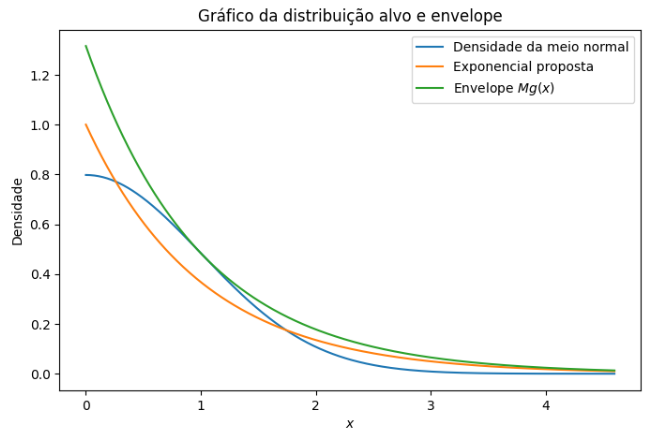

### Passo 2: obter o valor da constante $M$.


Para encontrar $M$ tal que $g(x)$ seja envelope de $f(x)$, pregisamos garantir que:

$$
f(x)\leq Mg(x), \quad x\geq 0.
$$

Portanto, precisamos garantir que $M$ seja, pelo menos o máximo da razão entre $f(x)$ e $g(x)$, dada por:

$$
r(x)=\frac{f(x)}{g(x)}
=\sqrt{\frac{2}{\pi}}e^{-x^2/2 + x}.
$$

Para encontrar um ponto crítico, derivamos $r(x)$ aplicando a regra da cadeia e obtemos a expressão:

$$
r'(x)
=\sqrt{\frac{2}{\pi}}e^{-x^2/2+x}(1-x).
$$

Agora, vamos igualar essa expressão a $0$ para obter o valor crítico de $x$:

$$
r'(x)=0
\quad\Longleftrightarrow\quad
1-x=0
\quad\Longleftrightarrow\quad x=1.
$$

Uma vez que e^{-x^2/2+x} é sempre um valor positivo, temos que a única forma de a expressão ser igual a $0$ ocorre quando $1 - x = 0$, ou seja, quando $x = 1$, como demonstrado acima.

Vamos agora derivar a expressão novamente para observar se o ponto crítico é ponto de máximo:

$$
r''(x)
=\sqrt{\frac{2}{\pi}}e^{-x^2/2+x}
\left[(1-x)^2-1\right].
$$

Indexando em $x=1$, temos:

$$
r''(1)=-\sqrt{\frac{2}{\pi}}e^{1/2}<0.
$$

Portanto, temos que $x=1$ é ponto de máximo, logo:

$$
\begin{aligned}
M&=\max_{x\geq 0}\frac{f(x)}{g(x)}\\
&=r(1)\\
&=\sqrt{\frac{2}{\pi}}e^{-1/2+1}\\
&=\sqrt{\frac{2e}{\pi}}\\
&\approx 1.3155.
\end{aligned}
$$

Assim, encontramos o menor valor possível da constante $M$.

### Passo 3: obter a probabilidade de aceitação.

Vamos agora encontrar a probabilidade de aceitação, isto é, dado um candidato $Y\sim\operatorname{Exp}(1)$, a probabilidade de aceitá-lo é:

$$
p_{\mathrm{aceitação}}(Y)
=\frac{f(Y)}{Mg(Y)}.
$$

Substituindo $f$, $g$ e $M$, temos:

$$
\begin{aligned}
p_{\mathrm{aceitação}}(Y)
&=\frac{\sqrt{\frac{2}{\pi}}e^{-Y^2/2}}
{\sqrt{\frac{2e}{\pi}}e^{-Y}}\\[5pt]
&=\exp\left(-\frac{Y^2}{2}+Y-\frac12\right)\\[5pt]
&=\exp\left(-\frac{(Y-1)^2}{2}\right).
\end{aligned}
$$

Assim, a probabilidade de aceitação é dada por:

$$
\boxed{
p_{\mathrm{aceitação}}(Y)
=e^{-(Y-1)^2/2}.
}
$$

### Passo 4: implementar o algoritmo

Vamos agora implementar o algoritmo:

1. Geramos um valor de $Y\sim\operatorname{Exp}(1)$.
2. Geramos um valor de $U\sim\operatorname{Uniform}(0,1)$.
3. Aceitamos $Y$ se:

$$
U\leq e^{-(Y-1)^2/2}.
$$

Caso contrário, rejeitamos o valor de $Y$ proposto.

4. Repetimos os passos anteriores até a obtenção de uma amostra de tamanho n da distribuição alvo.


In [6]:
np.random.seed(850560)

def half_normal_rejection(n):
    M = np.sqrt(2 / np.pi) * np.exp(0.5) # Constante normalizadora

    samples = [] # Array para guardar a amostra

    while len(samples) < n:
        # Proposta: Exponential(1)
        Y = np.random.exponential(scale=1)

        # Variável aleatória uniforme
        U = np.random.uniform(0, 1)

        # Probabilidade de aceitação
        acceptance_prob = (np.sqrt(2 / np.pi) * np.exp(-Y**2 / 2) / (M * np.exp(-Y)))

        if U <= acceptance_prob: # Aceita valor simulado apenas se prob_aceitação => U
            samples.append(Y)

    return np.array(samples)

X_rejection = half_normal_rejection(10000) # Amostra a ser simulada

X_rejection

array([0.06735864, 0.72779856, 0.36979404, ..., 0.77178146, 0.50998185,
       1.58272665])

In [7]:
print("A média amostral considerando o método da rejeição simples é de:", round(X_rejection.mean(), 4))
print("A variância amostral considerando o método da rejeição simples é de:", round(X_rejection.var(), 4))

A média amostral considerando o método da rejeição simples é de: 0.7876
A variância amostral considerando o método da rejeição simples é de: 0.3525


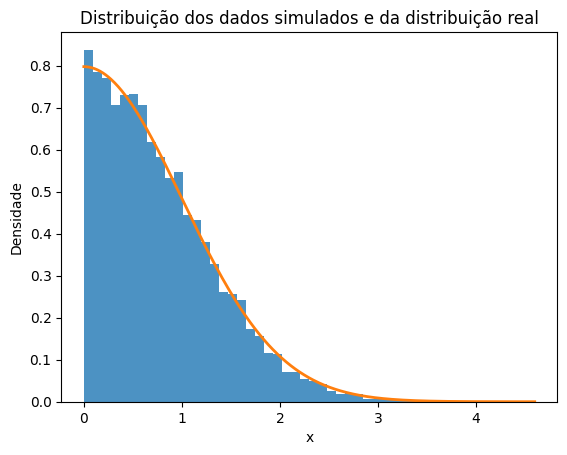

In [8]:
# Plotando o histograma para os dados simulados
plt.hist(X_rejection, bins=50, density=True, alpha=0.8)

x = np.linspace(0, max(X_rejection), 500) # Suavizador da meio normal
plt.plot(x, halfnorm.pdf(x), linewidth=2) # Plotando a distribuição meio normal padrão

plt.xlabel("x")
plt.ylabel("Densidade")
plt.title("Distribuição dos dados simulados e da distribuição real")
plt.show()

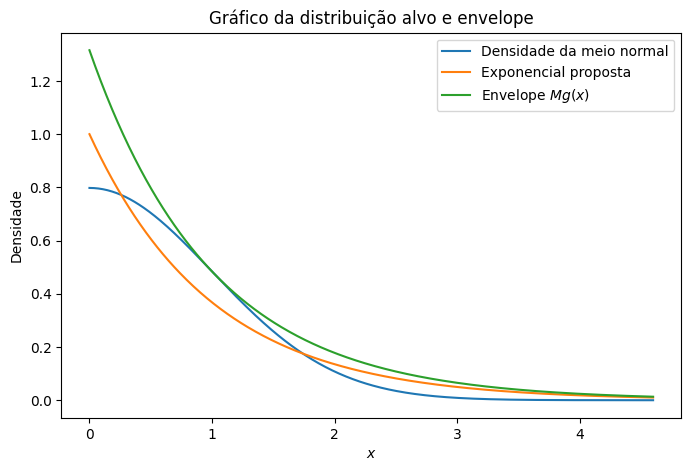

In [9]:
# Grid
x = np.linspace(0, max(X_rejection), 500)

# Densidade alvo: Half-Normal(0,1)
f = halfnorm.pdf(x)

# Densidade proposta: Exponential(1)
g = np.exp(-x)

# Envelope: M*g(x)
M = np.sqrt(2 / np.pi) * np.exp(0.5)
envelope = M * g

# Plotando o gráfico
plt.figure(figsize=(8, 5))

plt.plot(x, f, label="Densidade da meio normal")
plt.plot(x, g, label="Exponencial proposta")
plt.plot(x, envelope, label=r"Envelope $M g(x)$")

plt.xlabel("$x$")
plt.ylabel("Densidade")
plt.title("Gráfico da distribuição alvo e envelope")
plt.legend()

plt.show()

## **3. Comparação de métodos**

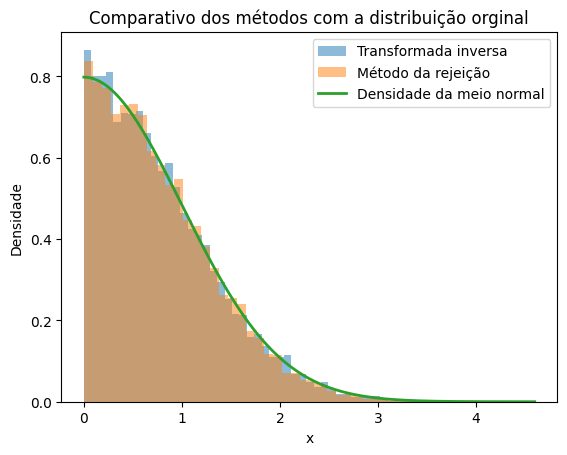

In [10]:
plt.hist(X_inverse, bins=50, density=True, alpha=0.5, label="Transformada inversa")
plt.hist(X_rejection, bins=50, density=True, alpha=0.5, label="Método da rejeição")

x = np.linspace(0, max(max(X_inverse), max(X_rejection)), 500)
plt.plot(x, halfnorm.pdf(x), linewidth=2, label="Densidade da meio normal")

plt.title("Comparativo dos métodos com a distribuição orginal")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()

**Testes de aderência (α = 5%)**

$H0:$ **X ~ Half-Normal(0,1)**

$H1:$ **X** segue outra distribuição.

In [11]:
n_bins = 10 # Número de partições

# Divisão das partições baseadas nos quantis da distribuição teórica
bins = halfnorm.ppf(np.linspace(0, 1, n_bins + 1))

# Frequências observadas
observed_inverse, _ = np.histogram(X_inverse, bins=bins)
observed_rejection, _ = np.histogram(X_rejection, bins=bins)

# Partições amostrais com mesma probabilidade teórica
expected_inverse = np.ones(n_bins) * len(X_inverse) / n_bins
expected_rejection = np.ones(n_bins) * len(X_rejection) / n_bins

# Testes qui-quadrado
chi_inverse = chisquare(observed_inverse, expected_inverse)
chi_rejection = chisquare(observed_rejection, expected_rejection)

print("Teste qui-quadrado - Método da transformada inversa")
print("Estatística de teste:", round(chi_inverse.statistic,4))
print("valor-p:", round(chi_inverse.pvalue,4))

print("\nTeste qui-quadrado - Método da rejeição")
print("Estatística de teste:", round(chi_rejection.statistic,4))
print("valor-p:", round(chi_rejection.pvalue,4))

Teste qui-quadrado - Método da transformada inversa
Estatística de teste: 17.554
valor-p: 0.0407

Teste qui-quadrado - Método da rejeição
Estatística de teste: 21.7
valor-p: 0.0099


Uma vez que o **valor-p < α** para ambos os métodos, temos que, com base no teste qui-quadrado, a hipótese nula é rejeitada e concluímos que as amostras não seguem uma distribuição meio normal padrão.

In [12]:
# Teste de Kolmogorov-Smirnov (KS)
ks_inverse = kstest(X_inverse, halfnorm.cdf) # Método da transformada inversa
ks_rejection = kstest(X_rejection, halfnorm.cdf) # Método da rejeição

print("Teste KS para o método transformada inversa")
print("Estatística de teste:", round(ks_inverse.statistic,4))
print("valor-p:", round(ks_inverse.pvalue,4))

print("\nTeste KS para o método da rejeição")
print("Estatística de teste:", round(ks_rejection.statistic,4))
print("valor-p:", round(ks_rejection.pvalue,4))

Teste KS para o método transformada inversa
Estatística de teste: 0.0104
valor-p: 0.2284

Teste KS para o método da rejeição
Estatística de teste: 0.0096
valor-p: 0.3123


Como o **valor-p > α** para ambos os métodos, temos que, com base no teste KS, a rejeição da hipótese nula não ocorre e concluímos que as amostras simuladas são provenientes da distribuição meio normal padrão.

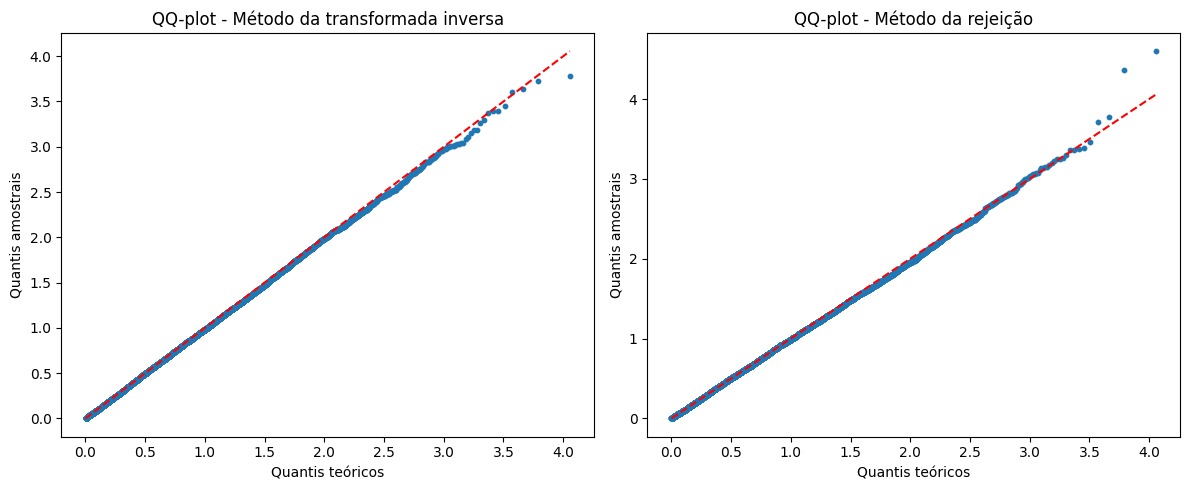

In [13]:
# Tamanho dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Ordenando as amostras
X_inverse_sorted = np.sort(X_inverse)
X_rejection_sorted = np.sort(X_rejection)

# Probabilidades teóricas
p_inverse = (np.arange(1, len(X_inverse) + 1) - 0.5) / len(X_inverse)
p_rejection = (np.arange(1, len(X_rejection) + 1) - 0.5) / len(X_rejection)

# Theoretical Half-Normal quantiles
q_inverse = halfnorm.ppf(p_inverse)
q_rejection = halfnorm.ppf(p_rejection)

# Método da transformada inversa
axes[0].scatter(q_inverse, X_inverse_sorted, s=10)
axes[0].plot([0, max(q_inverse)],[0, max(q_inverse)], linestyle="--", color = "red")

axes[0].set_title("QQ-plot - Método da transformada inversa")
axes[0].set_xlabel("Quantis teóricos")
axes[0].set_ylabel("Quantis amostrais")

# Método da rejeição
axes[1].scatter(q_rejection, X_rejection_sorted, s=10)
axes[1].plot([0, max(q_rejection)],[0, max(q_rejection)], linestyle="--", color = "red")

axes[1].set_title("QQ-plot - Método da rejeição")
axes[1].set_xlabel("Quantis teóricos")
axes[1].set_ylabel("Quantis amostrais")

plt.tight_layout()
plt.show()

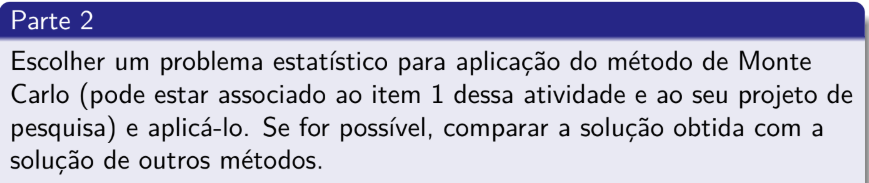

Uma das principais aplicações dos métodos de Monte-Carlo está na estimação da média e variância da distribuição meio normal, no código a seguir, temos um exemplo dessa aplicação para a meio normal padrão.

### Passo 1: especificação da distribuição alvo

Considerando a distribuição meio normal padrão do exercício anterior, temos que esta pode ser obtida considerando o módulo da distribuição normal padrão usual dada por:

$$
Z\sim N(0,1),
$$

ou seja,

$$
X=|Z|\sim\operatorname{HalfNormal}(0,1).
$$

Assim, podemos obter amostras da distribuição meio normal padrão apenas simulando valores da normal padrão e obtendo seu módulo.

### Passo 2: obter a média real

Vamos obter a média integrando a variável de interesse, cuja expressão usual é a seguinte:

$$
\mathbb{E}(X)=\int_{-\infty}^{\infty}xf_X(x)\,dx.
$$

Considerando o suporte da distribuição meio normal de $[0,\infty)$,

$$
\begin{aligned}
\mathbb{E}(X)
&=\sqrt{\frac{2}{\pi}}
\int_0^\infty xe^{-x^2/2}\,dx.
\end{aligned}
$$

substituindo

$$
u=\frac{x^2}{2},
\qquad du=x\,dx,
$$

temos

$$
\begin{aligned}
\mathbb{E}(X)
&=\sqrt{\frac{2}{\pi}}\int_0^\infty e^{-u}\,du\\
&=\sqrt{\frac{2}{\pi}}
\left[-e^{-u}\right]_0^\infty\\
&=\sqrt{\frac{2}{\pi}}.
\end{aligned}
$$

Assim, a média teórica é dada por:

$$
\boxed{\mathbb{E}(X)=\sqrt{\frac{2}{\pi}}
\approx 0.7979.}
$$

### Passo 3: obter a variância

Sabemos que

$$
\operatorname{Var}(X)
=\mathbb{E}(X^2)-[\mathbb{E}(X)]^2.
$$

Então, vamos calcular o segundo momento:

$$
\begin{aligned}
\mathbb{E}(X^2)
&=\int_0^\infty x^2f_X(x)\,dx\\
&=\sqrt{\frac{2}{\pi}}
\int_0^\infty x^2e^{-x^2/2}\,dx.
\end{aligned}
$$

Utilizando a integral por partes, temos:

$$
u=x,\qquad dv=xe^{-x^2/2}\,dx.
$$

Logo

$$
du=dx,\qquad v=-e^{-x^2/2}.
$$

Portanto, temos:

$$
\begin{aligned}
\int_0^\infty x^2e^{-x^2/2}\,dx
&=\left[-xe^{-x^2/2}\right]_0^\infty
+\int_0^\infty e^{-x^2/2}\,dx\\
&=\sqrt{\frac{\pi}{2}}.
\end{aligned}
$$

E

$$
\mathbb{E}(X^2)
=\sqrt{\frac{2}{\pi}}\sqrt{\frac{\pi}{2}}
=1.
$$

Substituindo o segundo momento na variância, temos:

$$
\begin{aligned}
\operatorname{Var}(X)
&=1-\left(\sqrt{\frac{2}{\pi}}\right)^2\\
&=1-\frac{2}{\pi}.
\end{aligned}
$$

Assim, a variância teórica é dada por

$$
\boxed{\operatorname{Var}(X)=1-\frac{2}{\pi}
\approx 0.3634.}
$$

### Passo 4: gerar uma amostra de Monte Carlo

Vamos gerar um amostra com $n = 10000$:

$$
Z_i\overset{\mathrm{iid}}{\sim}N(0,1),
\qquad i=1,\ldots,10000,
$$

e definir

$$
X_i=|Z_i|.
$$

Como o módulo da normal padrão segue uma distribuição meio normal padrão, temos que as observações da amostra de Monte Carlo são da distribuição de interesse.

### Passo 5: estimar a média e a variância

Para uma amostra de tamanho $n$, temos que a estimativa de Monte Carlo para a média é dada por:

$$
\widehat{\mu}_n
=\frac{1}{n}\sum_{i=1}^{n}X_i.
$$

Enquanto a da variância é

$$
\widehat{\sigma}_n^2
=\frac{1}{n-1}\sum_{i=1}^{n}
(X_i-\widehat{\mu}_n)^2.
$$

Calculamos essas estimativas para diferentes tamanhos amostrais

$$
n\in\{100,500,1000,2000,5000,10000\}.
$$

No código, cada amostra corresponde às $n$ primeiras observações do conjunto de dados simulado.

### Passo 6: avaliar os erros de estimação

Para cada tamanho de amostra, calculamos o erro absoluto para a média e variância:
$$
E_{\mu}(n)
=\left|\widehat{\mu}_n-\sqrt{\frac{2}{\pi}}\right|,
\quad
E_{\sigma^2}(n)
=\left|\widehat{\sigma}_n^2-
\left(1-\frac{2}{\pi}\right)\right|.
$$

A fim de quantificar a diferença entre as estimativas e o valor real destas.

In [14]:
# Definindo a semente
np.random.seed(850560)

# Média e variância teóricas
mean_theoretical = np.sqrt(2 / np.pi)
variance_theoretical = 1 - 2 / np.pi

# Tamanho de amostra das simulações de Monte Carlo
sample_sizes = [100, 500, 1000, 2000, 5000, 10000]

results = []

# Gerando uma amostra aleatória da distribuição meio normal.
X = np.abs(np.random.normal(0, 1, 10000))

for n in sample_sizes:
    sample = X[:n] # Selecionando as primeiras n observações de X

    # Obtendo as médias e variâncias estimadas com o Método de Monte Carlo
    mean_mc = np.mean(sample)
    variance_mc = np.var(sample, ddof=1)

    results.append({"Tamanho amostral": n, "Média estimada": mean_mc,
        "Média real": mean_theoretical, "Variância estimada": variance_mc,
        "Variância real": variance_theoretical, "Erro absoluto da média": abs(
            mean_mc - mean_theoretical), "Erro absoluto da variância": abs(
            variance_mc - variance_theoretical)})

results_df = pd.DataFrame(results) # Armazenando os resultados em um dataframe

print(results_df.round(4).to_string(index=False)) # Printando os resultados

 Tamanho amostral  Média estimada  Média real  Variância estimada  Variância real  Erro absoluto da média  Erro absoluto da variância
              100          0.7977      0.7979              0.3915          0.3634                  0.0002                      0.0281
              500          0.7977      0.7979              0.3672          0.3634                  0.0002                      0.0038
             1000          0.7964      0.7979              0.3716          0.3634                  0.0015                      0.0082
             2000          0.7992      0.7979              0.3602          0.3634                  0.0013                      0.0032
             5000          0.8070      0.7979              0.3718          0.3634                  0.0091                      0.0084
            10000          0.7964      0.7979              0.3649          0.3634                  0.0015                      0.0016


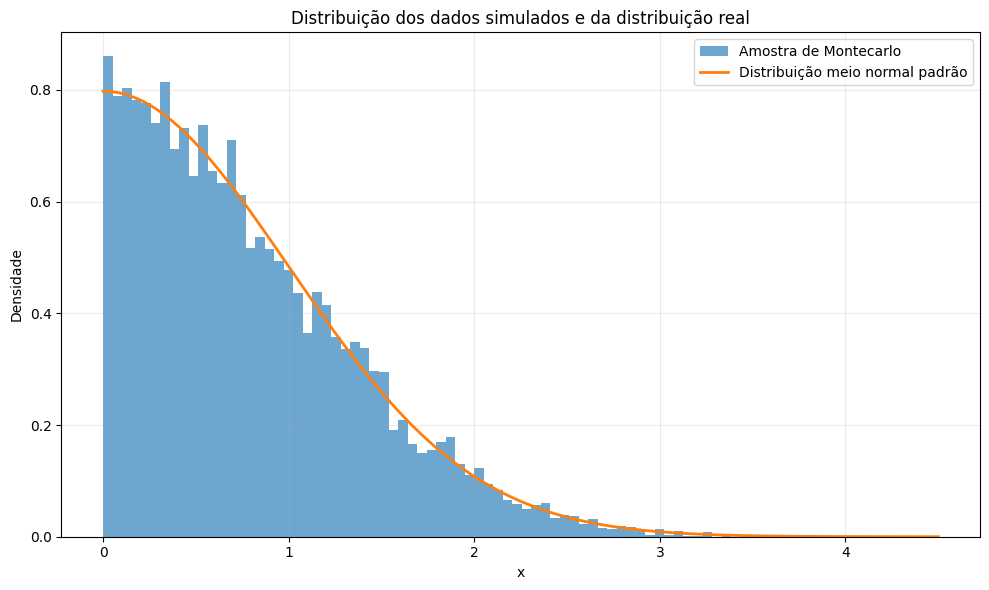

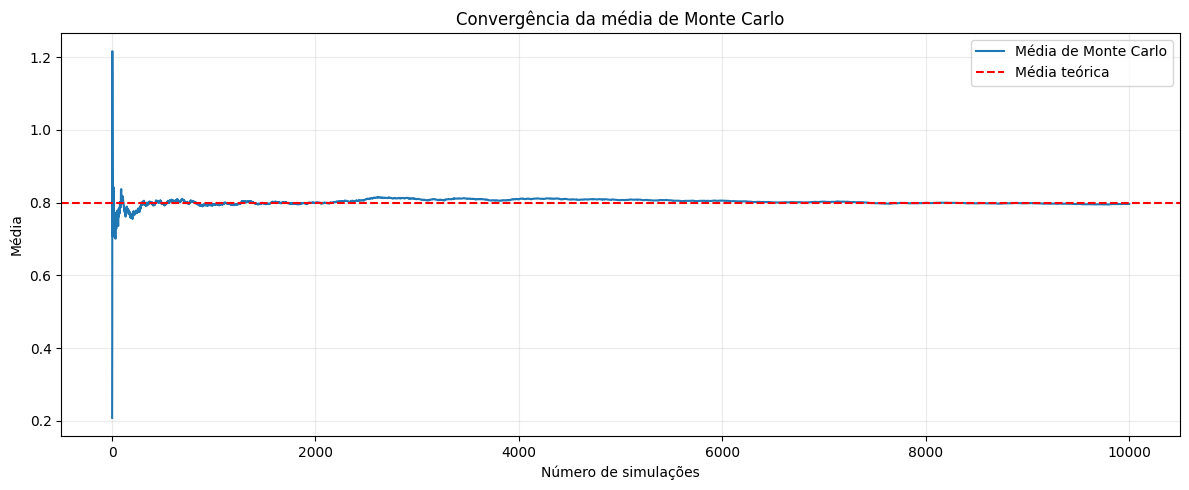

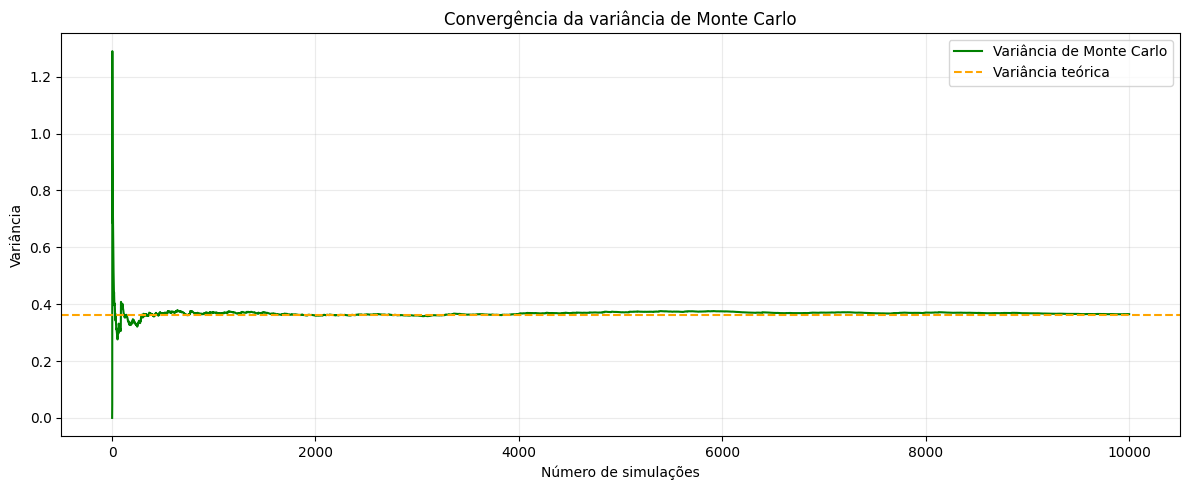

In [15]:
# --------------------------------------------------
# Histograma com a densidade teórica
# --------------------------------------------------

plt.figure(figsize=(10, 6))
plt.hist(X, bins=80, density=True, alpha=0.65, label="Amostra de Montecarlo")

x = np.linspace(0, 4.5, 500)

plt.plot(x, halfnorm.pdf(x), linewidth=2, label="Distribuição meio normal padrão")

plt.xlabel("x")
plt.ylabel("Densidade")
plt.title("Distribuição dos dados simulados e da distribuição real")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Convergência das estimativas
# --------------------------------------------------

sample_sizes_full = np.arange(1, len(X) + 1) # Tamanho da amostra X

# Média amostral a medida que X cresce
cumulative_mean = np.cumsum(X) / sample_sizes_full

# Variância cumulativa
cumulative_variance = (np.cumsum(X**2) / sample_sizes_full - cumulative_mean**2)

plt.figure(figsize=(12, 5))

plt.plot(sample_sizes_full, cumulative_mean, label="Média de Monte Carlo")
plt.axhline(mean_theoretical, linestyle="--", color = "red", label="Média teórica")
plt.xlabel("Número de simulações")
plt.ylabel("Média")
plt.title("Convergência da média de Monte Carlo")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.plot(sample_sizes_full, cumulative_variance, color = "green", label="Variância de Monte Carlo")
plt.axhline(variance_theoretical, linestyle="--", color = "orange", label="Variância teórica")
plt.xlabel("Número de simulações")
plt.ylabel("Variância")
plt.title("Convergência da variância de Monte Carlo")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [16]:
print("A média amostral considerando a transformada inversa é de:", round(X_inverse.mean(), 4))
print("A média amostral considerando o método da rejeição simples é de:", round(X_rejection.mean(), 4))
print("A média amostral considerando o método de Monte Carlo é de:", round(X.mean(), 4))

A média amostral considerando a transformada inversa é de: 0.7846
A média amostral considerando o método da rejeição simples é de: 0.7876
A média amostral considerando o método de Monte Carlo é de: 0.7964


In [17]:
print("A variância amostral considerando a transformada inversa é de:", round(X_inverse.var(), 4))
print("A variância amostral considerando o método da rejeição simples é de:", round(X_rejection.var(), 4))
print("A variância amostral considerando o método de Monte Carlo é de:", round(X.var(), 4))

A variância amostral considerando a transformada inversa é de: 0.354
A variância amostral considerando o método da rejeição simples é de: 0.3525
A variância amostral considerando o método de Monte Carlo é de: 0.3649


In [18]:
n_bins = 10 # Número de partições

# Divisão das partições baseadas nos quantis da distribuição teórica
bins = halfnorm.ppf(np.linspace(0, 1, n_bins + 1))

# Frequências observadas
observed_mc, _ = np.histogram(X, bins=bins)

# Partições amostrais com mesma probabilidade teórica
expected_mc = np.ones(n_bins) * len(X) / n_bins

# Testes qui-quadrado
chi_mc = chisquare(observed_mc, expected_mc)

print("Teste qui-quadrado - Método de Monte Carlo")
print("Estatística de teste:", round(chi_mc.statistic,4))
print("valor-p:", round(chi_mc.pvalue,4))

Teste qui-quadrado - Método de Monte Carlo
Estatística de teste: 6.324
valor-p: 0.7071


In [19]:
# Teste de Kolmogorov-Smirnov (KS)
ks_inverse = kstest(X, halfnorm.cdf) # Método de Monte Carlo

print("Teste KS para o método de Monte Carlo")
print("Estatística de teste:", round(ks_inverse.statistic,4))
print("valor-p:", round(ks_inverse.pvalue,4))

Teste KS para o método de Monte Carlo
Estatística de teste: 0.0069
valor-p: 0.7261


Como podemos observar, a média e variância amostrais do método de Monte Carlo são muito mais próximas dos parâmetros teóricos que nos outros dois métodos para n = 10000. Além disso, ao nível de significância $\alpha$ = 5%, o método de Monte Carlo foi o único que não rejeitou $H_0$ no teste qui-quadrado.